# This notebook is for cleaning the data we have already stored in the raw and created the tables to interim in csv
- Folder Specifications
- raw - never changed data directly from the scraped websites
- interim - data extracted from the raw folders in csv files for explicit reading and parquet files for faster access and less storage
- clean - cleaned data after cleaning from the table



- Every change go to a decision log: it contains what we did , what we assumed, and why.
- First we look at the problem it has whether it is outliers,missing values or duplicates and then decide to apply anything to the data 

### The path we follow

| Step | The path we followed |
|---|---|
| 1 | What did we get? (setup and a first look) | 
| 2 | Are the values written correctly? |
| 3 | Are there rows that were never written? |
| 4 | Are there columns or rows that are not part of our project? |
| 5 | Why are values missing, and should we fill them? |
| 6 | Which values are far from the rest, and why? |
| 7 | Is the same thing in the data twice? |
| 8 | Can the NAV table and the TER table be joined? |
| 9 | Save the clean tables and the log |

Cheap checks come first (types, absent rows) and the expensive ones (fuzzy matching) come last.

# 1) Setup and a first look

We read the two tables that the interim notebook saved. We use the Parquet files because they load fast and remember the column types. The CSV copies hold the same rows

In [1]:
import os, re
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
os.makedirs("clean", exist_ok=True)

nav_raw = pd.read_parquet("interim/nav/nav_midcap_combined.parquet")
ter_raw = pd.read_parquet("interim/ter/ter_combined.parquet")

# copying data so we dont change the direct raw files
nav = nav_raw.copy() 
ter = ter_raw.copy()
print("NAV:", nav.shape, "| TER:", ter.shape)

NAV: (206239, 11) | TER: (70019, 27)


In [2]:
# This function logs all the methods we done from first
decision_log = []
# rows_affected = how many rows (or values) the decision changed, 0 when we only looked or dropped columns
def log(columns,problem,action,method_used,rows_affected=None):
    decision_log.append({"columns": columns, "problem": problem, "action": action, "method_used": method_used, "rows_affected": rows_affected})

row_counts = []
# Tracks number of rows in each table after each step. This is useful for the report.
# This function counts the number of rows in each table and appends it to the row_counts list along with the step name.
def count_rows(step):
    """Remembers how many rows each table has right now."""
    row_counts.append({"step": step, "nav_rows": len(nav), "ter_rows": len(ter)})

count_rows("loaded from interim")

Before changing anything, we  look at the tables.
- We first check the data types as df.isna() and df.dtypes to see if the data types are correct and if there are any missing values.
- df.isna() alone only finds the missing values fo which the null values are detectable in the pandas library. We need to check the dtypes of each columns to know whether they are correct or not. If the dtypes are not correct then we need to check whether there are any missing values that cause the dtype change

In [3]:
display(nav.head())
print("-"*40)
display(ter.head())
print("-"*40)
print(nav.dtypes)
print("-"*40)
print(ter.dtypes)

,Scheme Code,NAV Name,Plan,Option,ISIN Div Payout/ISIN Growth,ISIN Div Reinvestment,Net Asset Value,Date,Category,AMC,MF_ID
0,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,59.155,01-Apr-2019,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
1,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.9318,02-Apr-2019,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
2,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.3833,03-Apr-2019,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
3,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.1116,04-Apr-2019,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
4,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.4231,05-Apr-2019,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13


----------------------------------------


,NSDLSchemeCode,Scheme_Name,SchemeType_Desc,SchemeCat_Desc,R_BaseTER,TER_Year,TER_Date,R_6A_B,R_6A_C,R_GST,R_TER,D_BaseTER,D_6A_B,D_6A_C,D_GST,D_TER,MF_ID,Month,strCat,R_BER,R_BrokerageCost,R_TransactionCost,R_StatutoryLevies,D_BER,D_BrokerageCost,D_TransactionCost,D_StatutoryLevies
0,<NA>,Aditya Birla Sun Life MIDCAP Fund,Open Ended,Equity Scheme - Mid Cap Fund,1.8800,2018-2019,2019-01-01,0.0000,0.0500,0.1700,2.1100,1.0800,0.0000,0.0500,0.1700,1.3100,3,01-2019,17,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,<NA>,Baroda Mid-cap Fund,Open Ended,Equity Scheme - Mid Cap Fund,2.5000,2018-2019,2019-01-01,0.3000,0.0500,0.2200,3.0700,1.4000,0.0000,0.0500,0.2200,1.6700,4,01-2019,17,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,<NA>,DSP Midcap Fund - Regular Plan,Open Ended,Equity Scheme - Mid Cap Fund,1.8000,2018-2019,2019-01-01,0.1100,0.0500,0.1800,2.1400,0.9200,0.0000,0.0500,0.1500,1.1200,6,01-2019,17,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,<NA>,HDFC MID-CAP OPPORTUNITIES FUND,Open Ended,Equity Scheme - Mid Cap Fund,1.7600,2018-2019,2019-01-01,0.1800,0.0500,0.1600,2.1500,0.9100,0.0000,0.0500,0.1600,1.1200,9,01-2019,17,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,<NA>,QUANT MID CAP FUND,Open Ended,Equity Scheme - Mid Cap Fund,2.5000,2018-2019,2019-01-01,0.0000,0.0000,0.2300,2.7300,2.0000,0.0000,0.0000,0.2300,2.2300,13,01-2019,17,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


----------------------------------------
Scheme Code                      str
NAV Name                         str
Plan                             str
Option                           str
ISIN Div Payout/ISIN Growth      str
ISIN Div Reinvestment            str
Net Asset Value                  str
Date                             str
Category                         str
AMC                              str
MF_ID                          int64
dtype: object
----------------------------------------
NSDLSchemeCode               string
Scheme_Name                  string
SchemeType_Desc              string
SchemeCat_Desc               string
R_BaseTER                    string
TER_Year                     string
TER_Date             datetime64[us]
R_6A_B                       string
R_6A_C                       string
R_GST                        string
R_TER                        string
D_BaseTER                    string
D_6A_B                       string
D_6A_C                       

## 2. Checking whether the data types and values are written correctly

- Somebody upstream decided how to write "we do not have this value", and almost none of those choices produce a real `NaN`. Common ones are `N.A.`, `-`, a blank space, `0`, `-1` or `-999`, and a date like `1900-01-01` like the lectures said.
- So we should check how the file write no value in the place
- The dangerous ones are the numeric markers. A `0` in a NAV column raises no error, `isna()` does not count it, and the average quietly goes down. So we check how the file writes "no value" **before** we report any missing count.

# NAV Data type check

In [4]:
# NAV should be a floating point numbet ,but it is stored as a string.We need to convert it to number. We use pd.to_numeric to convert the string to a number.
as_number = pd.to_numeric(nav["Net Asset Value"], errors="coerce").astype("float64")
bad = nav.loc[as_number.isna(), "Net Asset Value"]
print("values that are not a number:", len(bad))
print(bad.value_counts(dropna=False).head(10))

# a NAV can not be zero or negative, so check the numbers that did convert
print("zero or negative:", int((as_number <= 0).sum()))
print(as_number.describe())

values that are not a number: 0
Series([], Name: count, dtype: int64)
zero or negative: 0
count    206239.000000
mean        191.205617
std         493.307409
min           6.420000
25%          25.252850
50%          53.841000
75%         116.889050
max        5080.280600
Name: Net Asset Value, dtype: float64


In [5]:
nav["Net Asset Value"] = as_number
# Making the date as a datetime object so that we can do time series analysis on it. We use pd.to_datetime to convert the string to a datetime object.
nav["Date"] = pd.to_datetime(nav["Date"], format="%d-%b-%Y", errors="coerce")
print("dates from", nav["Date"].min().date(), "to", nav["Date"].max().date())

log("Net Asset Value", "string instead of number", "converted to float64", "pd.to_numeric", len(nav))
log("Date", "string instead of datetime", "converted to datetime", "pd.to_datetime", len(nav))

dates from 2019-01-01 to 2026-09-30


In [6]:
# log for the NAV value check (step 2): nothing was wrong, and we write that down too
log("Net Asset Value", "zero, negative or non-numeric NAV", "none found, nothing changed", "pd.to_numeric(errors='coerce') and a <= 0 check", int(as_number.isna().sum() + (as_number <= 0).sum()))

### TER DATA CHECKS
- We check the TER table for the same problems. The TER is a percentage, so it should be a number between 0 and 100. The date should be a real date.

In [7]:
# There are three columns in the ter data that tell the same time thing so we combine them into one column. We use pd.to_datetime to convert the string to a datetime object.
ter["Date"] = pd.to_datetime(ter["TER_Date"],format="%Y-%m-%d", errors="coerce")
ter.drop(columns=["TER_Year", "Month", "TER_Date"], inplace=True)
# to conver na values to nan the pandas can detect
ter= ter.replace([""," ","NULL","null","None","none","N/A","n/a","NA","-"], np.nan)
# To convert the values containing float values that are string to convert them to float
ter_numeric_cols = ["R_BaseTER","R_6A_B","R_6A_C","R_GST","R_TER","D_BaseTER","D_6A_B","D_6A_C","D_GST","D_TER","R_BER","R_BrokerageCost","D_BER","D_BrokerageCost","D_TransactionCost","R_TransactionCost","D_StatutoryLevies","R_StatutoryLevies"]
for col in ter_numeric_cols:
    ter[col] = pd.to_numeric(ter[col], errors="coerce").astype("float64")  

display(ter.head())
print(ter.dtypes)

/tmp/ipykernel_8513/3343483315.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ter.drop(columns=["TER_Year", "Month", "TER_Date"], inplace=True)


,NSDLSchemeCode,Scheme_Name,SchemeType_Desc,SchemeCat_Desc,R_BaseTER,R_6A_B,R_6A_C,R_GST,R_TER,D_BaseTER,D_6A_B,D_6A_C,D_GST,D_TER,MF_ID,strCat,R_BER,R_BrokerageCost,R_TransactionCost,R_StatutoryLevies,D_BER,D_BrokerageCost,D_TransactionCost,D_StatutoryLevies,Date
0,<NA>,Aditya Birla Sun Life MIDCAP Fund,Open Ended,Equity Scheme - Mid Cap Fund,1.88,0.00,0.05,0.17,2.11,1.08,0.0,0.05,0.17,1.31,3,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
1,<NA>,Baroda Mid-cap Fund,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.30,0.05,0.22,3.07,1.40,0.0,0.05,0.22,1.67,4,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
2,<NA>,DSP Midcap Fund - Regular Plan,Open Ended,Equity Scheme - Mid Cap Fund,1.80,0.11,0.05,0.18,2.14,0.92,0.0,0.05,0.15,1.12,6,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
3,<NA>,HDFC MID-CAP OPPORTUNITIES FUND,Open Ended,Equity Scheme - Mid Cap Fund,1.76,0.18,0.05,0.16,2.15,0.91,0.0,0.05,0.16,1.12,9,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
4,<NA>,QUANT MID CAP FUND,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.00,0.00,0.23,2.73,2.00,0.0,0.00,0.23,2.23,13,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01


NSDLSchemeCode               string
Scheme_Name                  string
SchemeType_Desc              string
SchemeCat_Desc               string
R_BaseTER                   float64
R_6A_B                      float64
R_6A_C                      float64
R_GST                       float64
R_TER                       float64
D_BaseTER                   float64
D_6A_B                      float64
D_6A_C                      float64
D_GST                       float64
D_TER                       float64
MF_ID                         int64
strCat                        int64
R_BER                       float64
R_BrokerageCost             float64
R_TransactionCost           float64
R_StatutoryLevies           float64
D_BER                       float64
D_BrokerageCost             float64
D_TransactionCost           float64
D_StatutoryLevies           float64
Date                 datetime64[us]
dtype: object


In [8]:
# log for the TER type fixes (step 2)
placeholders = ["", " ", "NULL", "null", "None", "none", "N/A", "n/a", "NA", "-"]
n_markers = int(ter_raw[ter_numeric_cols].isin(placeholders).sum().sum())
n_text = int(ter_raw[ter_numeric_cols].notna().sum().sum())

log("TER_Date, TER_Year, Month", "three columns that hold the same date", "kept one datetime column Date and dropped the other two", "pd.to_datetime", 0)
log("TER numeric columns", f"numbers stored as text ({n_text} values)", "converted to float64", "pd.to_numeric", n_text)
log("TER numeric columns", f"empty markers written as text ({n_markers} values)", "replaced by NaN", "replace with a list of markers", n_markers)

## Is the scraping worked for all years or some rows came missing


In [9]:
nav.head()

,Scheme Code,NAV Name,Plan,Option,ISIN Div Payout/ISIN Growth,ISIN Div Reinvestment,Net Asset Value,Date,Category,AMC,MF_ID
0,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,59.1550,2019-04-01,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
1,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.9318,2019-04-02,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
2,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.3833,2019-04-03,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
3,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.1116,2019-04-04,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13
4,120841,quant Mid Cap Fund - Growth Option - Direct Plan,Direct Plan,Growth Option,INF966L01887,,58.4231,2019-04-05,Open Ended Schemes ( Equity Scheme - Mid Cap F...,quant Mutual Fund,13


seeing the available and missing years for each scheme is useful for the report, so we will have a list of missing schemes and a list of available schemes for each year.

In [10]:
all_years = sorted(nav['Date'].dt.year.dropna().unique())
print("All years in the data:", all_years)
scheme_years = (nav.groupby("Scheme Code")["Date"].apply(lambda x: sorted(x.dt.year.dropna().unique())).reset_index(name = "avaialable_years"))
scheme_years["scheme_name"] = scheme_years["Scheme Code"].map(lambda x: nav[nav["Scheme Code"] == x]["AMC"].iloc[0] if not nav[nav["Scheme Code"] == x]["AMC"].empty else None)
scheme_years["mf_id"] = scheme_years["Scheme Code"].map(lambda x: nav[nav["Scheme Code"] == x]["MF_ID"].iloc[0] if not nav[nav["Scheme Code"] == x]["MF_ID"].empty else None)
scheme_years["missing_years"] = scheme_years["avaialable_years"].apply(lambda x: [year for year in all_years if year not in x])

scheme_years["years_present_count"] = scheme_years["avaialable_years"].apply(len)
scheme_years["total_years"] = len(all_years)

scheme_years.head()
display(scheme_years.groupby("mf_id").agg({"scheme_name": "first", "avaialable_years": "first", "missing_years": "first", "years_present_count": "first", "total_years": "first"}).reset_index())

All years in the data: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


,mf_id,scheme_name,avaialable_years,missing_years,years_present_count,total_years
0,3,Aditya Birla Sun Life Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
1,4,Baroda BNP Paribas Mutual Fund,"[2019, 2020, 2021, 2022]","[2023, 2024, 2025, 2026]",4,8
2,6,DSP Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
3,9,HDFC Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
4,13,quant Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
5,16,JM Financial Mutual Fund,"[2022, 2023, 2024, 2025, 2026]","[2019, 2020, 2021]",5,8
6,17,Kotak Mahindra Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
7,18,LIC Mutual Fund,"[2023, 2024, 2025, 2026]","[2019, 2020, 2021, 2022]",4,8
8,20,ICICI Prudential Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8
9,21,Nippon India Mutual Fund,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",[],8,8


In [11]:
ter.head()

,NSDLSchemeCode,Scheme_Name,SchemeType_Desc,SchemeCat_Desc,R_BaseTER,R_6A_B,R_6A_C,R_GST,R_TER,D_BaseTER,D_6A_B,D_6A_C,D_GST,D_TER,MF_ID,strCat,R_BER,R_BrokerageCost,R_TransactionCost,R_StatutoryLevies,D_BER,D_BrokerageCost,D_TransactionCost,D_StatutoryLevies,Date
0,<NA>,Aditya Birla Sun Life MIDCAP Fund,Open Ended,Equity Scheme - Mid Cap Fund,1.88,0.00,0.05,0.17,2.11,1.08,0.0,0.05,0.17,1.31,3,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
1,<NA>,Baroda Mid-cap Fund,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.30,0.05,0.22,3.07,1.40,0.0,0.05,0.22,1.67,4,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
2,<NA>,DSP Midcap Fund - Regular Plan,Open Ended,Equity Scheme - Mid Cap Fund,1.80,0.11,0.05,0.18,2.14,0.92,0.0,0.05,0.15,1.12,6,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
3,<NA>,HDFC MID-CAP OPPORTUNITIES FUND,Open Ended,Equity Scheme - Mid Cap Fund,1.76,0.18,0.05,0.16,2.15,0.91,0.0,0.05,0.16,1.12,9,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
4,<NA>,QUANT MID CAP FUND,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.00,0.00,0.23,2.73,2.00,0.0,0.00,0.23,2.23,13,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01


In [12]:
all_ter_years = sorted(ter['Date'].dt.year.dropna().unique())
print("All years in the data:", all_ter_years)
scheme_ter_years = (ter.groupby("MF_ID")["Date"].apply(lambda x: sorted(x.dt.year.dropna().unique())).reset_index(name = "avaialable_years"))
scheme_ter_years["scheme_name"] = scheme_ter_years["MF_ID"].map(lambda x: ter[ter["MF_ID"] == x]["Scheme_Name"].iloc[0] if not ter[ter["MF_ID"] == x]["Scheme_Name"].empty else None)
scheme_ter_years["mf_id"] = scheme_ter_years["MF_ID"]
scheme_ter_years["missing_years"] = scheme_ter_years["avaialable_years"].apply(lambda x: [year for year in all_ter_years if year not in x]) 
scheme_ter_years["years_present_count"] = scheme_ter_years["avaialable_years"].apply(len)
scheme_ter_years["total_years"] = len(all_ter_years)
display(scheme_ter_years)


All years in the data: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


,MF_ID,avaialable_years,scheme_name,mf_id,missing_years,years_present_count,total_years
0,3,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",Aditya Birla Sun Life MIDCAP Fund,3,[],8,8
1,4,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",Baroda Mid-cap Fund,4,[],8,8
2,6,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",DSP Midcap Fund - Regular Plan,6,[],8,8
3,9,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",HDFC MID-CAP OPPORTUNITIES FUND,9,[],8,8
4,13,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",QUANT MID CAP FUND,13,[],8,8
5,16,"[2022, 2023, 2024, 2025, 2026]",JM Midcap Fund,16,"[2019, 2020, 2021]",5,8
6,17,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",Kotak Emerging Equity Scheme,17,[],8,8
7,18,"[2023, 2024, 2025, 2026]",LIC MF Mid Cap Fund,18,"[2019, 2020, 2021, 2022]",4,8
8,20,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",ICICI Prudential Midcap Fund,20,[],8,8
9,21,"[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]",Reliance Growth Fund,21,[],8,8


In [13]:
# log for the missing years (step 3). We only report them, we never invent rows
n_nav_missing = int(scheme_years.groupby("mf_id")["missing_years"].first().map(len).gt(0).sum())
n_ter_missing = int(scheme_ter_years["missing_years"].map(len).gt(0).sum())
log("Date (NAV)", f"{n_nav_missing} fund houses have no rows in some years", "reported only, no rows invented", "years present per MF_ID", 0)
log("Date (TER)", f"{n_ter_missing} fund houses have no rows in some years", "reported only, no rows invented", "years present per MF_ID", 0)

## 4. Columns or rows that are not part of the data
this part is about dropping columns and rows that are not part of our project. We have to drop it only if we can write the reason in one line, and write that line in the log. If something is a helper that we still need we keep it but make sure it never goes into a chart by accident.

In [14]:
nav.columns

Index(['Scheme Code', 'NAV Name', 'Plan', 'Option',
       'ISIN Div Payout/ISIN Growth', 'ISIN Div Reinvestment',
       'Net Asset Value', 'Date', 'Category', 'AMC', 'MF_ID'],
      dtype='str')

In [15]:
# Scheme Code is not required for NAV because mf_id is unique for each scheme and can be used to identify the scheme. So we can drop the Scheme Code column from the nav dataframe.
nav.drop(columns=["Scheme Code"], inplace=True)
# The Plan and option and AMC columns are sufficient and provide same data as NAV Name so we drop it
nav.drop(columns=["NAV Name"], inplace=True)
# ISIN code and ISIN DIv Reinvestment is used for identifying the scheme and is not required for our analysis, so we drop it
nav.drop(columns=["ISIN Div Payout/ISIN Growth"], inplace=True)
nav.drop(columns=["ISIN Div Reinvestment"], inplace=True)
# Category is not required for our analysis, so we drop it
nav.drop(columns=["Category"], inplace=True)
# the removed data
display(nav.head())
print(nav.info())
print(nav.dtypes)



/tmp/ipykernel_8513/3357144356.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  nav.drop(columns=["Scheme Code"], inplace=True)
/tmp/ipykernel_8513/3357144356.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  nav.drop(columns=["NAV Name"], inplace=True)
/tmp/ipykernel_8513/3357144356.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  nav.drop(columns=["ISIN Div Payout/ISIN Growth"], inplace=True)
/tmp/ipykernel_8513/3357144356.py:7: Pandas4Warning: The inplace keyword in Da

,Plan,Option,Net Asset Value,Date,AMC,MF_ID
0,Direct Plan,Growth Option,59.1550,2019-04-01,quant Mutual Fund,13
1,Direct Plan,Growth Option,58.9318,2019-04-02,quant Mutual Fund,13
2,Direct Plan,Growth Option,58.3833,2019-04-03,quant Mutual Fund,13
3,Direct Plan,Growth Option,58.1116,2019-04-04,quant Mutual Fund,13
4,Direct Plan,Growth Option,58.4231,2019-04-05,quant Mutual Fund,13


<class 'pandas.DataFrame'>
RangeIndex: 206239 entries, 0 to 206238
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Plan             206239 non-null  str           
 1   Option           206239 non-null  str           
 2   Net Asset Value  206239 non-null  float64       
 3   Date             206239 non-null  datetime64[us]
 4   AMC              206239 non-null  str           
 5   MF_ID            206239 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 17.9 MB
None
Plan                          str
Option                        str
Net Asset Value           float64
Date               datetime64[us]
AMC                           str
MF_ID                       int64
dtype: object


In [16]:
nav = nav[[ "MF_ID","Plan", "Option", "AMC", "Date", "Net Asset Value"]]
nav = nav.rename(columns={"Net Asset Value": "NAV","AMC": "Mutual_Fund_Company"})
nav.head()

,MF_ID,Plan,Option,Mutual_Fund_Company,Date,NAV
0,13,Direct Plan,Growth Option,quant Mutual Fund,2019-04-01,59.1550
1,13,Direct Plan,Growth Option,quant Mutual Fund,2019-04-02,58.9318
2,13,Direct Plan,Growth Option,quant Mutual Fund,2019-04-03,58.3833
3,13,Direct Plan,Growth Option,quant Mutual Fund,2019-04-04,58.1116
4,13,Direct Plan,Growth Option,quant Mutual Fund,2019-04-05,58.4231


In [17]:
# log for the NAV columns removed and renamed (step 4)
log("Scheme Code, NAV Name, ISIN Div Payout/ISIN Growth, ISIN Div Reinvestment, Category", "not needed: MF_ID, Plan and Option already identify the scheme", "dropped 5 columns", "column review", 0)
log("Net Asset Value, AMC", "names that are not clear", "renamed to NAV and Mutual_Fund_Company", "rename", 0)

- Ter data checks by removing the unnecessary columns in ter

In [18]:
ter.head()

,NSDLSchemeCode,Scheme_Name,SchemeType_Desc,SchemeCat_Desc,R_BaseTER,R_6A_B,R_6A_C,R_GST,R_TER,D_BaseTER,D_6A_B,D_6A_C,D_GST,D_TER,MF_ID,strCat,R_BER,R_BrokerageCost,R_TransactionCost,R_StatutoryLevies,D_BER,D_BrokerageCost,D_TransactionCost,D_StatutoryLevies,Date
0,<NA>,Aditya Birla Sun Life MIDCAP Fund,Open Ended,Equity Scheme - Mid Cap Fund,1.88,0.00,0.05,0.17,2.11,1.08,0.0,0.05,0.17,1.31,3,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
1,<NA>,Baroda Mid-cap Fund,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.30,0.05,0.22,3.07,1.40,0.0,0.05,0.22,1.67,4,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
2,<NA>,DSP Midcap Fund - Regular Plan,Open Ended,Equity Scheme - Mid Cap Fund,1.80,0.11,0.05,0.18,2.14,0.92,0.0,0.05,0.15,1.12,6,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
3,<NA>,HDFC MID-CAP OPPORTUNITIES FUND,Open Ended,Equity Scheme - Mid Cap Fund,1.76,0.18,0.05,0.16,2.15,0.91,0.0,0.05,0.16,1.12,9,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
4,<NA>,QUANT MID CAP FUND,Open Ended,Equity Scheme - Mid Cap Fund,2.50,0.00,0.00,0.23,2.73,2.00,0.0,0.00,0.23,2.23,13,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01


In [19]:
# NSDL Scheme Code is not required for TER because mf_id is unique for each scheme and can be used to identify the scheme. So we can drop the Scheme Code column from the ter dataframe.
ter.drop(columns=["NSDLSchemeCode"], inplace=True)
# Scheme Type_Desc,SchemeCat_Desc is not required for our analysis, so we drop it
ter.drop(columns=["SchemeType_Desc", "SchemeCat_Desc"], inplace=True)
# strCat is used and we know it comes from equity scheme and schemes so we drop it
ter.drop(columns=["strCat"], inplace=True)
ter.head()


/tmp/ipykernel_8513/4013432033.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ter.drop(columns=["NSDLSchemeCode"], inplace=True)
/tmp/ipykernel_8513/4013432033.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ter.drop(columns=["SchemeType_Desc", "SchemeCat_Desc"], inplace=True)
/tmp/ipykernel_8513/4013432033.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ter.drop(columns=["strCat"], inplace=True)


,Scheme_Name,R_BaseTER,R_6A_B,R_6A_C,R_GST,R_TER,D_BaseTER,D_6A_B,D_6A_C,D_GST,D_TER,MF_ID,R_BER,R_BrokerageCost,R_TransactionCost,R_StatutoryLevies,D_BER,D_BrokerageCost,D_TransactionCost,D_StatutoryLevies,Date
0,Aditya Birla Sun Life MIDCAP Fund,1.88,0.00,0.05,0.17,2.11,1.08,0.0,0.05,0.17,1.31,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
1,Baroda Mid-cap Fund,2.50,0.30,0.05,0.22,3.07,1.40,0.0,0.05,0.22,1.67,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
2,DSP Midcap Fund - Regular Plan,1.80,0.11,0.05,0.18,2.14,0.92,0.0,0.05,0.15,1.12,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
3,HDFC MID-CAP OPPORTUNITIES FUND,1.76,0.18,0.05,0.16,2.15,0.91,0.0,0.05,0.16,1.12,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01
4,QUANT MID CAP FUND,2.50,0.00,0.00,0.23,2.73,2.00,0.0,0.00,0.23,2.23,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-01-01


In [20]:
important_cols = ["MF_ID","Scheme_Name","Date","R_TER","D_TER"]
ter_main = ter[important_cols]
ter_main.head()


,MF_ID,Scheme_Name,Date,R_TER,D_TER
0,3,Aditya Birla Sun Life MIDCAP Fund,2019-01-01,2.11,1.31
1,4,Baroda Mid-cap Fund,2019-01-01,3.07,1.67
2,6,DSP Midcap Fund - Regular Plan,2019-01-01,2.14,1.12
3,9,HDFC MID-CAP OPPORTUNITIES FUND,2019-01-01,2.15,1.12
4,13,QUANT MID CAP FUND,2019-01-01,2.73,2.23


In [21]:
# log for the TER columns removed (step 4)
log("NSDLSchemeCode, SchemeType_Desc, SchemeCat_Desc, strCat", "not needed: MF_ID identifies the scheme and type and category are the same for all rows", "dropped 4 columns", "column review", 0)
log("Scheme_Name, Date, R_TER, D_TER", "the TER columns of the main analysis", "kept as ter_main, all other columns stay in ter_complement", "column selection", 0)

In [22]:
ter_main.dtypes

MF_ID                   int64
Scheme_Name            string
Date           datetime64[us]
R_TER                 float64
D_TER                 float64
dtype: object

## 5. Why are values missing, and should we fill them?
1. Compare a column between the rows that have the value and the rows that do not (a Welch t-test for numbers, a chi-square test for categories or years). If the groups differ, it is not MCAR.
2. Fit a logistic regression with "is it missing?" as the answer and the other columns as the predictors.
3. Little's test, which checks all numeric columns together.

**Then the decision.** Filling is only licensed when the mechanism allows it, and every method has a cost: the mean keeps the average but squashes the spread, regression inflates the correlation, a random draw is different every time. The course scores each method by hiding some values we know, filling them, and measuring the error (RMSE). We will do that for one column.

- Checking for the missing values and imputing them in the data

In [23]:
# NAV DATA
nav.info()

<class 'pandas.DataFrame'>
RangeIndex: 206239 entries, 0 to 206238
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   MF_ID                206239 non-null  int64         
 1   Plan                 206239 non-null  str           
 2   Option               206239 non-null  str           
 3   Mutual_Fund_Company  206239 non-null  str           
 4   Date                 206239 non-null  datetime64[us]
 5   NAV                  206239 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 17.9 MB


In [24]:
#  We will also restrict our analysis to growth options as mentioned in the project proposal.
print(nav["Option"].value_counts())

Option
Growth                                                                                49248
IDCW                                                                                  46732
Growth Option                                                                         33106
IDCW Option                                                                           31222
                                                                                      11948
GROWTH                                                                                 7644
Income Distribution cum Capital Withdrawal                                             3828
IDCW - Payout & Re-investment of Income Distribution cum capital withdrawal option     3822
Bonus Option                                                                           3822
IDCW (Income Distribution CUM Capital Withdrawal)                                      3822
Direct IDCW                                                              

In [25]:
growth_options = ["Growth","Growth Option","GROWTH","Regular Growth","Direct Growth"]
nav  = nav[nav["Option"].isin(growth_options)]
nav.info()

<class 'pandas.DataFrame'>
Index: 93824 entries, 0 to 206114
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   MF_ID                93824 non-null  int64         
 1   Plan                 93824 non-null  str           
 2   Option               93824 non-null  str           
 3   Mutual_Fund_Company  93824 non-null  str           
 4   Date                 93824 non-null  datetime64[us]
 5   NAV                  93824 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 8.7 MB


In [26]:
# log for the growth filter (step 4/5): these are rows removed
log("Option", "the table also holds dividend (IDCW) rows, the project uses the growth option only", "kept the growth rows only", "Option isin growth_options", len(nav_raw) - len(nav))
count_rows("only growth options kept")

In [27]:
plan = nav["Plan"].fillna("").str.lower()
option = nav["Option"].fillna("").str.lower()

mismatch = (
    (plan.str.contains(r"\bdirect\b") & option.str.contains(r"\bregular\b")) |
    (plan.str.contains(r"\bregular\b") & option.str.contains(r"\bdirect\b"))
)

print("Mismatched rows:", int(mismatch.sum()))
display(nav.loc[mismatch, ["MF_ID", "Plan", "Option", "Mutual_Fund_Company"]].drop_duplicates())

Mismatched rows: 0


,MF_ID,Plan,Option,Mutual_Fund_Company


- So by the above code we can see that the direct growth falls exactly under direct growth plans and regular growth falls under regular growth plans. So we can say that the data is consistent and we can use it for our analysis.

In [28]:
print("-"*40)
print(nav["Plan"].value_counts())
print(nav["Plan"].unique())
print("-"*40)
print(nav["Option"].value_counts())
print(nav["Option"].unique())
print("-"*40)
print(nav["Mutual_Fund_Company"].unique())
print("-"*40)
print(nav["MF_ID"].unique())
print(nav["MF_ID"].nunique())
print("-"*40)
#as the nav is float it will not contain the null values

----------------------------------------
Plan
Direct Plan     46912
Regular Plan    46912
Name: count, dtype: int64
<ArrowStringArray>
['Direct Plan', 'Regular Plan']
Length: 2, dtype: str
----------------------------------------
Option
Growth            49248
Growth Option     33106
GROWTH             7644
Direct Growth      1913
Regular Growth     1913
Name: count, dtype: int64
<ArrowStringArray>
['Growth Option', 'Growth', 'GROWTH', 'Direct Growth', 'Regular Growth']
Length: 5, dtype: str
----------------------------------------
<ArrowStringArray>
[                'quant Mutual Fund',          'JM Financial Mutual Fund',
        'Kotak Mahindra Mutual Fund',                   'LIC Mutual Fund',
      'ICICI Prudential Mutual Fund',          'Nippon India Mutual Fund',
                   'SBI Mutual Fund',                  'Tata Mutual Fund',
                'Taurus Mutual Fund',    'Franklin Templeton Mutual Fund',
                   'UTI Mutual Fund', 'Aditya Birla Sun Life Mutual 

In [29]:
# By the above cell output we see there is no empty value in the data so there are no missing values 
#As we have all options as growth we can safely remove the Option Column from the nav dataframe
nav = nav.drop(columns=["Option"])
nav.head()

,MF_ID,Plan,Mutual_Fund_Company,Date,NAV
0,13,Direct Plan,quant Mutual Fund,2019-04-01,59.1550
1,13,Direct Plan,quant Mutual Fund,2019-04-02,58.9318
2,13,Direct Plan,quant Mutual Fund,2019-04-03,58.3833
3,13,Direct Plan,quant Mutual Fund,2019-04-04,58.1116
4,13,Direct Plan,quant Mutual Fund,2019-04-05,58.4231


In [30]:
# log for the Option column
log("Option", "after the filter every row is growth, so the column holds no information", "dropped the column", "value_counts", 0)

- Nav data contains no missing values so we don't have to fill any values in nav data

In [31]:
# log for the NAV missing check (step 5)
log("NAV", "missing values check", "no missing values, nothing to fill", "isna per column", int(nav.isna().sum().sum()))

### TER Data

In [32]:
ter_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 70019 entries, 0 to 70018
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   MF_ID        70019 non-null  int64         
 1   Scheme_Name  70019 non-null  string        
 2   Date         70019 non-null  datetime64[us]
 3   R_TER        70019 non-null  float64       
 4   D_TER        70019 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), string(1)
memory usage: 4.3 MB


In [33]:
def check_missingness(df, name, date_col="Date"):
    print(f"\n{name}: {len(df)} rows")
    display(df.isna().sum().rename("null_count").to_frame())

    rows_with_nulls = df.isna().any(axis=1)
    print("Rows with at least one null:", int(rows_with_nulls.sum()))

    for col in df.columns:
        if df[col].isna().any():
            first_date = df.loc[df[col].isna(), date_col].min()
            print(f"{col}: first null date = {first_date}")

    if date_col in df.columns:
        dated = df.loc[df[date_col].notna()].set_index(date_col)
        monthly_nulls = dated.isna().resample("MS").sum()
        monthly_nulls = monthly_nulls.loc[monthly_nulls.sum(axis=1) > 0]
        print("Monthly null counts:")
        display(monthly_nulls)

    # Show all rows that contain at least one null
    display(df.loc[rows_with_nulls])

check_missingness(ter_main, "TER Main")


TER Main: 70019 rows


,null_count
MF_ID,0
Scheme_Name,0
Date,0
R_TER,0
D_TER,0


Rows with at least one null: 0
Monthly null counts:


,MF_ID,Scheme_Name,R_TER,D_TER
Date,,,,


,MF_ID,Scheme_Name,Date,R_TER,D_TER


- IN the ter main frame we seperated from the ter there are no missing /null values in the data so we don't have to fill any values in ter main data
- So we check the ter_complement data also as it is useful for our analysis further

In [34]:
# log for the TER main missing check (step 5)
log("R_TER, D_TER", "missing values check", "no missing values, nothing to fill", "isna per column", int(ter_main[["R_TER", "D_TER"]].isna().sum().sum()))

In [35]:
complement_cols = [col for col in ter.columns if col not in ["R_TER","D_TER","Scheme_Name"]]
ter_complement = ter[complement_cols]
ter_complement.info()


<class 'pandas.DataFrame'>
RangeIndex: 70019 entries, 0 to 70018
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   R_BaseTER          64098 non-null  float64       
 1   R_6A_B             64098 non-null  float64       
 2   R_6A_C             64098 non-null  float64       
 3   R_GST              64098 non-null  float64       
 4   D_BaseTER          64098 non-null  float64       
 5   D_6A_B             64098 non-null  float64       
 6   D_6A_C             64098 non-null  float64       
 7   D_GST              64098 non-null  float64       
 8   MF_ID              70019 non-null  int64         
 9   R_BER              5921 non-null   float64       
 10  R_BrokerageCost    5921 non-null   float64       
 11  R_TransactionCost  5921 non-null   float64       
 12  R_StatutoryLevies  5921 non-null   float64       
 13  D_BER              5921 non-null   float64       
 14  D_BrokerageCost  

In [36]:
ter_complement = ter_complement[["MF_ID","Date","R_BaseTER","R_6A_B","R_6A_C","R_GST","D_BaseTER","D_6A_B","D_6A_C","D_GST","R_BER","R_BrokerageCost","D_BER","D_BrokerageCost","D_TransactionCost","R_TransactionCost","D_StatutoryLevies","R_StatutoryLevies"]]
ter_complement.info()

<class 'pandas.DataFrame'>
RangeIndex: 70019 entries, 0 to 70018
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   MF_ID              70019 non-null  int64         
 1   Date               70019 non-null  datetime64[us]
 2   R_BaseTER          64098 non-null  float64       
 3   R_6A_B             64098 non-null  float64       
 4   R_6A_C             64098 non-null  float64       
 5   R_GST              64098 non-null  float64       
 6   D_BaseTER          64098 non-null  float64       
 7   D_6A_B             64098 non-null  float64       
 8   D_6A_C             64098 non-null  float64       
 9   D_GST              64098 non-null  float64       
 10  R_BER              5921 non-null   float64       
 11  R_BrokerageCost    5921 non-null   float64       
 12  D_BER              5921 non-null   float64       
 13  D_BrokerageCost    5921 non-null   float64       
 14  D_TransactionCost

In [37]:
ter_complement = ter_complement.sort_values(by=["Date"]).reset_index(drop=True)
ter_complement.info()

<class 'pandas.DataFrame'>
RangeIndex: 70019 entries, 0 to 70018
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   MF_ID              70019 non-null  int64         
 1   Date               70019 non-null  datetime64[us]
 2   R_BaseTER          64098 non-null  float64       
 3   R_6A_B             64098 non-null  float64       
 4   R_6A_C             64098 non-null  float64       
 5   R_GST              64098 non-null  float64       
 6   D_BaseTER          64098 non-null  float64       
 7   D_6A_B             64098 non-null  float64       
 8   D_6A_C             64098 non-null  float64       
 9   D_GST              64098 non-null  float64       
 10  R_BER              5921 non-null   float64       
 11  R_BrokerageCost    5921 non-null   float64       
 12  D_BER              5921 non-null   float64       
 13  D_BrokerageCost    5921 non-null   float64       
 14  D_TransactionCost

/home/krish/project/dcv_midcap_returns_mutual_funds/venv/lib/python3.12/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(
/tmp/ipykernel_8513/2950206486.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


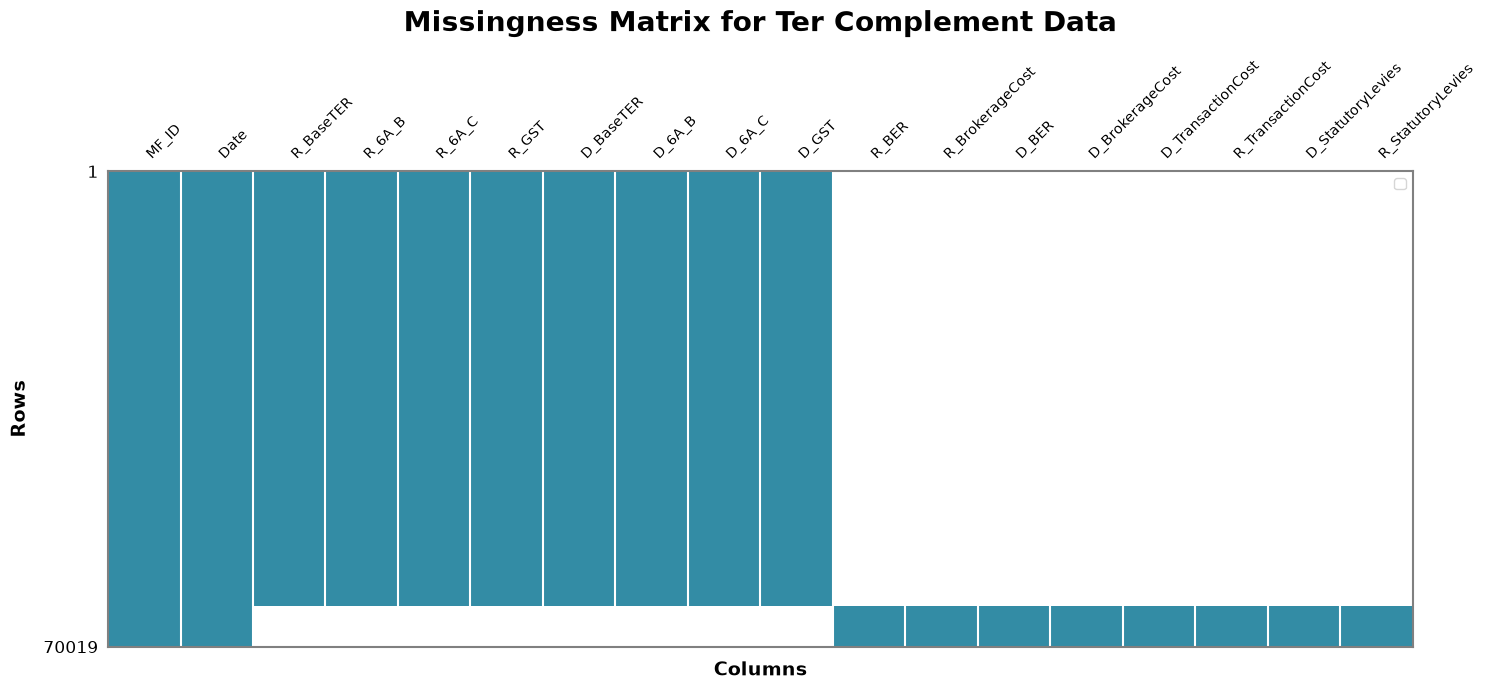

In [38]:
import missingno as msno
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(15,7))
msno.matrix(ter_complement,ax=ax, figsize=(15,7),color=(0.2,0.55,0.65),sparkline = True,fontsize=10)
ax.set_title("Missingness Matrix for Ter Complement Data",fontsize=20,fontweight="bold",pad=20)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("grey")
    spine.set_linewidth(1.5)
ax.set_xlabel("Columns",fontsize=14,fontweight="bold",labelpad=10)
ax.set_ylabel("Rows",fontsize=14,fontweight="bold",labelpad=10)
plt.tight_layout()
plt.legend()
plt.show()

- The matrix which is drawn for the data in sorted order shows that some missing values are there because of format change in the data so it also perfectly shows that the data has a point where the format changed and the new formats were introduced so it is a MAR mechanism and we cannot fill the missing values in the data as it will be biased to other data and we know that a perfect classifier on linear regression test means we cannot impute our data so we must cut down their analysis for the range possible or use any column that has complete data

In [39]:
# log for the TER complement (step 5): the empty parts follow the format change, so they are MAR and we do not fill them
log("R_BaseTER, R_6A_B, R_6A_C, R_GST, D_BaseTER, D_6A_B, D_6A_C, D_GST", "empty from the date the new BER format starts (MAR)", "not imputed, the analysis uses R_TER and D_TER which are complete", "missingness matrix + MAR reasoning", int(ter_complement["R_BaseTER"].isna().sum()))
log("R_BER, R_BrokerageCost, R_TransactionCost, R_StatutoryLevies, D_*", "empty before the new BER format starts (MAR)", "not imputed, used only for the period where they exist", "missingness matrix + MAR reasoning", int(ter_complement["R_BER"].isna().sum()))

## 6. OUTLIERS
| Cause | Example in our data | What we do |
|---|---|---|
| Entry error | a NAV typed 10 times too big | correct it if the true value is recoverable, otherwise set it to missing |
| Unit or format error | a value in the wrong scale | convert it, once the source is found |
| Real extreme | the market crashing on one day | **keep it**. Deleting it makes the data look calmer than the world is |
| Process change | a scheme merger or a bonus unit issue | treat the days before and after as different regimes |

- TER OUTLIERS DETECTION

scatter plot for R_TER with MF_ID as y-axis to see the outliers in the data

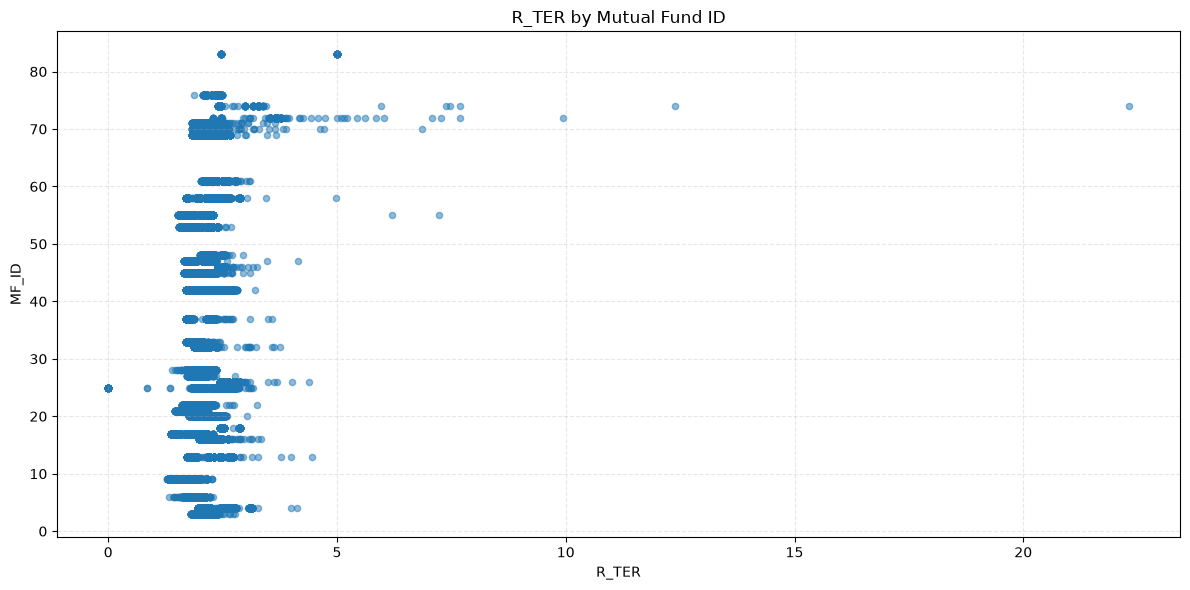

In [40]:
ter_plot = ter.dropna(subset=["R_TER", "MF_ID"])

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(ter_plot["R_TER"], ter_plot["MF_ID"], alpha=0.5, s=20)

ax.set_title("R_TER by Mutual Fund ID")
ax.set_xlabel("R_TER")
ax.set_ylabel("MF_ID")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Scatter plot for D_TER with MF_ID as y-axis to see the outliers in the data

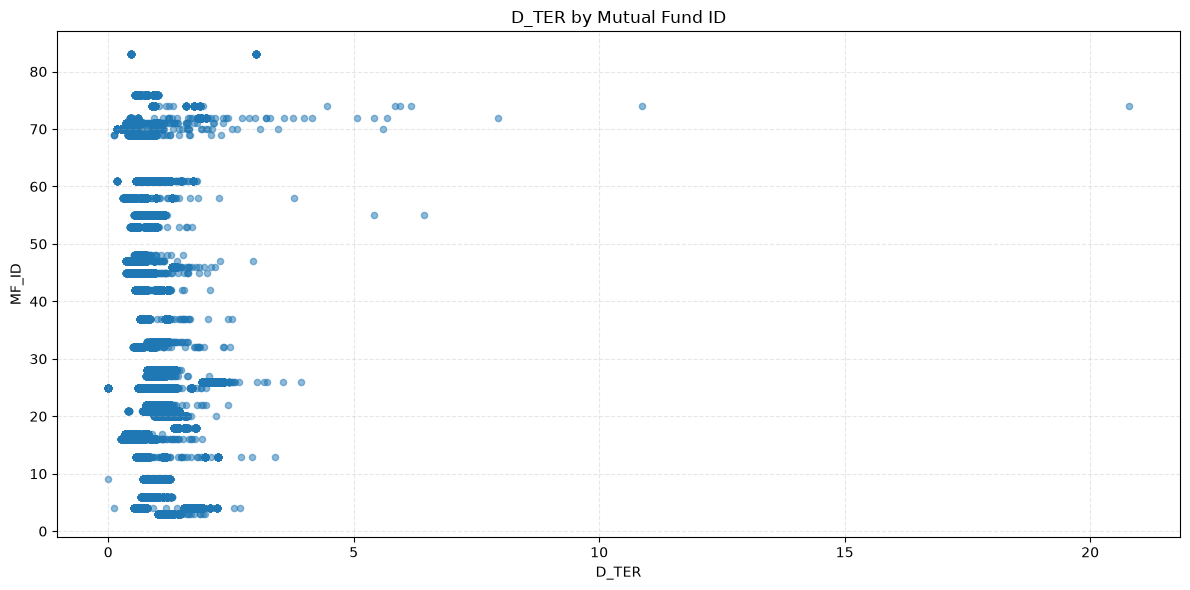

In [41]:
ter_plot = ter.dropna(subset=["D_TER", "MF_ID"])

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(ter_plot["D_TER"], ter_plot["MF_ID"], alpha=0.5, s=20)

ax.set_title("D_TER by Mutual Fund ID")
ax.set_xlabel("D_TER")
ax.set_ylabel("MF_ID")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

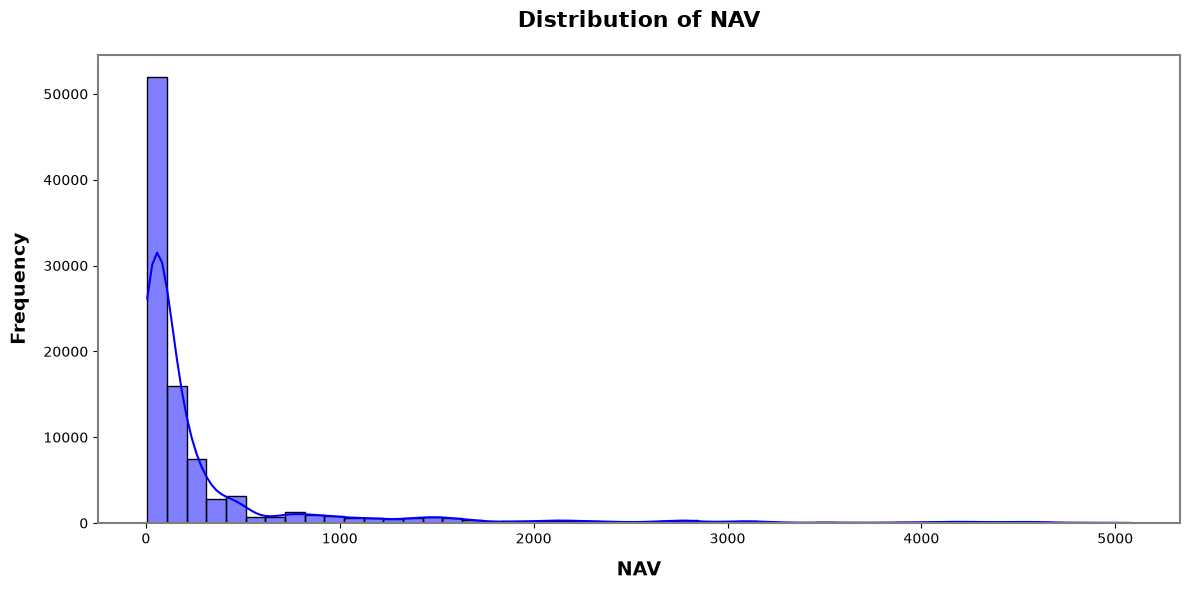

In [42]:
# Checking the data using Histograms
import seaborn as sns
fig,ax = plt.subplots(figsize=(12,6))
sns.histplot(data=nav,x="NAV",bins=50,kde=True,ax=ax,color="blue")
ax.set_title("Distribution of NAV",fontsize=16,fontweight="bold",pad=20)
ax.set_xlabel("NAV",fontsize=14,fontweight="bold",labelpad=10)
ax.set_ylabel("Frequency",fontsize=14,fontweight="bold",labelpad=10)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("grey")
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.show()

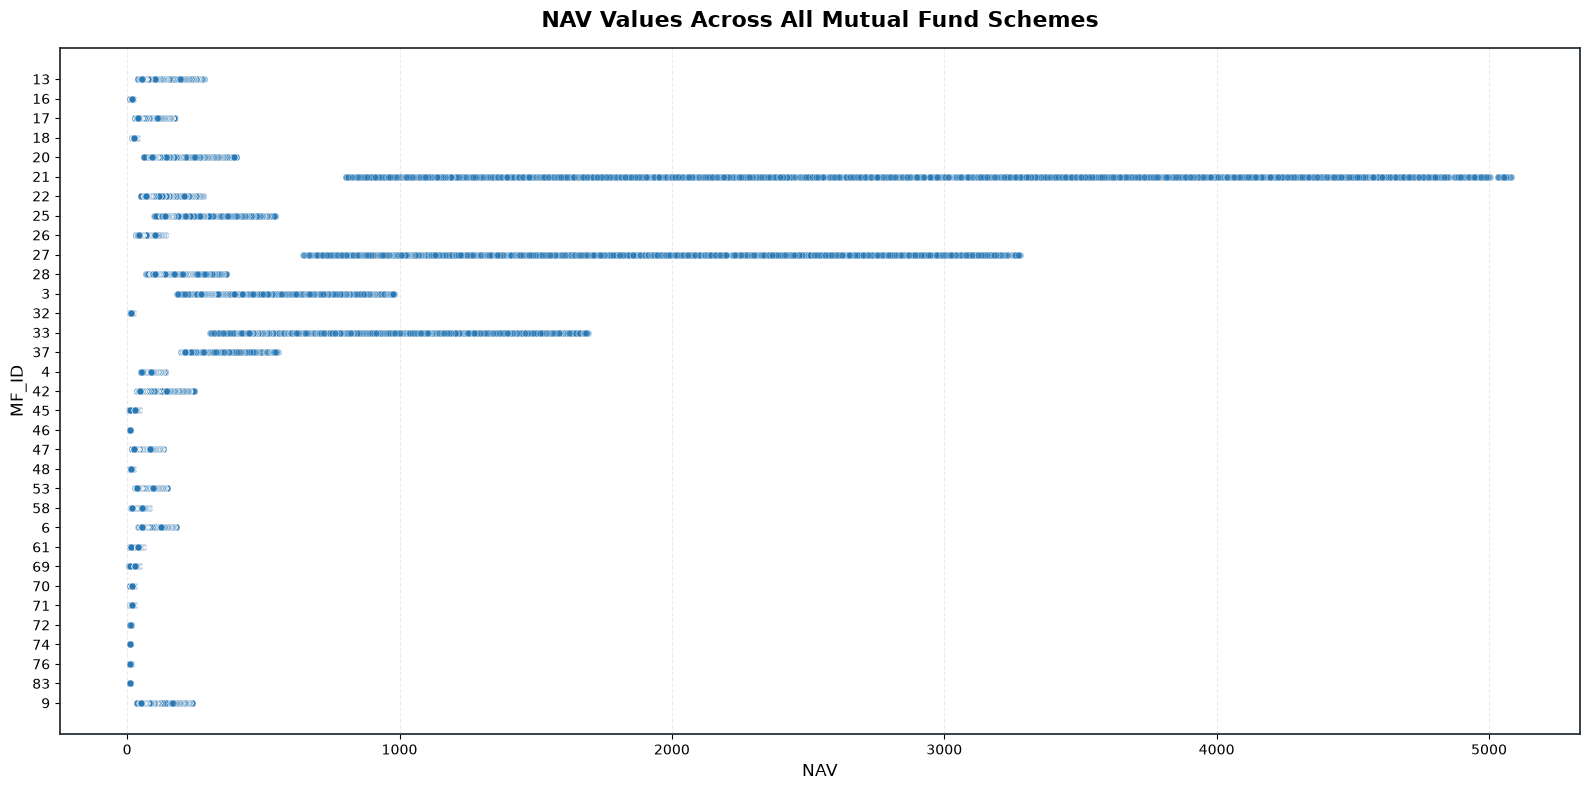

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

nav["Date"] = pd.to_datetime(nav["Date"], errors="coerce")

nav_plot = nav.dropna(subset=["MF_ID", "NAV", "Date"]).copy()

# Treat MF_ID as a category
nav_plot["MF_ID"] = nav_plot["MF_ID"].astype(str)

fig, ax = plt.subplots(figsize=(16, 8))

sns.scatterplot(
    data=nav_plot,
    x="NAV",
    y="MF_ID",
    color="#2878B5",
    alpha=0.5,
    s=25,
    ax=ax
)

ax.set_title(
    "NAV Values Across All Mutual Fund Schemes",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("NAV", fontsize=12)
ax.set_ylabel("MF_ID", fontsize=12)

ax.grid(axis="x", linestyle="--", alpha=0.25)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#263238")
    spine.set_linewidth(1.3)

plt.tight_layout()
plt.show()

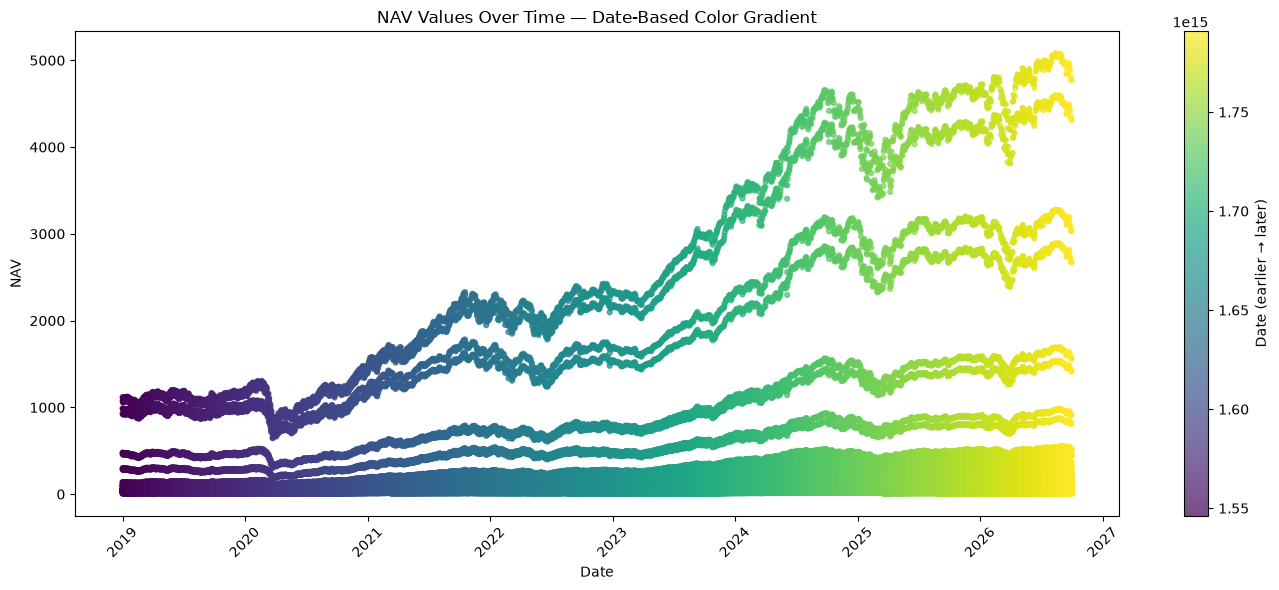

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

nav["Date"] = pd.to_datetime(nav["Date"], errors="coerce")
nav["NAV"] = pd.to_numeric(nav["NAV"], errors="coerce")

nav_plot = nav.dropna(subset=["Date", "NAV"]).copy()
nav_plot = nav_plot.sort_values("Date")

plt.figure(figsize=(14, 6))

scatter = plt.scatter(
    nav_plot["Date"],
    nav_plot["NAV"],
    c=nav_plot["Date"].astype("int64"),
    cmap="viridis",
    s=12,
    alpha=0.7
)

plt.colorbar(scatter, label="Date (earlier → later)")
plt.xlabel("Date")
plt.ylabel("NAV")
plt.title("NAV Values Over Time — Date-Based Color Gradient")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
!pip install scikit-learn

- A NAV level grows with time, so a high NAV is not an outlier (the 5000 NAV of one house is only a different scale). We test the daily return.
- A fund is one MF_ID with one Plan. Direct and Regular of the same house are two different price series, so the return is calculated inside MF_ID + Plan. (If we group by MF_ID only, the two plans are mixed and every row looks like a jump of +-10%.)-
- A return over a hole longer than 7 days is not a daily return, so we leave it empty.
- For TER we test R_TER, D_TER and the gap R_TER - D_TER.

In [46]:
# We now check the returns for each day in place of direct values to catch the outliers 
from sklearn.ensemble import IsolationForest
# the return is calculated inside each fund (MF_ID + Plan)
nav = nav.sort_values(["MF_ID", "Plan", "Date"])
nav["ret"] = nav.groupby(["MF_ID", "Plan"])["NAV"].pct_change(fill_method=None) * 100

# a return over a hole longer than 7 days is not a daily return
nav.loc[nav.groupby(["MF_ID", "Plan"])["Date"].diff().dt.days > 7, "ret"] = np.nan

# TER rows in time order inside each house, and the gap between the two plans
ter = ter.sort_values(["MF_ID", "Date"])
ter["gap"] = ter["R_TER"] - ter["D_TER"]

tests = {"ret": nav["ret"], "R_TER": ter["R_TER"], "D_TER": ter["D_TER"], "gap": ter["gap"]}
pd.DataFrame(tests).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ret,93758.0,0.073,1.066,-13.866,-0.403,0.156,0.649,7.045
R_TER,70019.0,2.025,0.430,0.000,1.780,1.990,2.300,22.310
D_TER,70019.0,0.870,0.455,0.000,0.570,0.780,1.080,20.790
gap,70019.0,1.155,0.508,-1.710,0.840,1.110,1.450,3.120


- so we now we detect using thee methods
- the first one is z- score method which uses the mean of std normal and detects the outliers based on the threshold if the |z| is greater than 3 then it is an outlier and we can remove it from the data
- the second method is the IQR method which uses the interquartile range to detect the outliers and we can remove it from the data so outside Q1-1.5IQR and Q3+1.5IQR is considered as outliers and we can remove it from the data
- we also use modified z-score but now we use median and MAD to detect the outliers

In [48]:
def detect_outliers_zscore(x, threshold=3):
    return ((x - x.mean()) / x.std()).abs() > threshold

def detect_outliers_iqr(x, factor=1.5):
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    return (x < q1 - factor * (q3 - q1)) | (x > q3 + factor * (q3 - q1))

def detect_outliers_modified_zscore(x, threshold=3.5):
    med = x.median()
    mad = (x - med).abs().median()
    # MAD can be 0 on tied data, then the method cannot judge
    return pd.Series(False, index=x.index) if mad == 0 else 0.6745 * (x - med).abs() / mad > threshold

# count of flagged rows per method and column
flag = {name: pd.DataFrame({"z-score": detect_outliers_zscore(x), "IQR": detect_outliers_iqr(x), "modified z": detect_outliers_modified_zscore(x)})
        for name, x in tests.items()}
counts = pd.DataFrame({name: f.sum() for name, f in flag.items()})
counts.loc["rows tested"] = [x.notna().sum() for x in tests.values()]
counts

,ret,R_TER,D_TER,gap
z-score,1345,1124,627,1049
IQR,4873,1286,3421,2321
modified z,2300,1171,2655,1143
rows tested,93758,70019,70019,70019


**Multivariate check.** Direct and Regular TER of a house move together. A pair can be normal in each column and strange as a pair. Isolation Forest (from the notes) looks at both columns at once. It marks the 1% most isolated rows and we look at them next to the other methods.

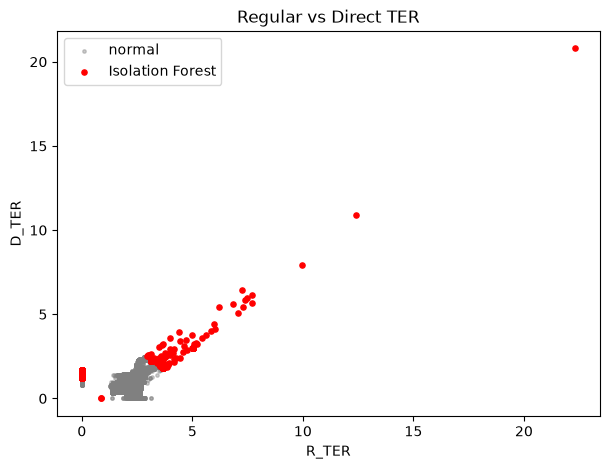

rows flagged by Isolation Forest: 695 | also flagged by IQR in R_TER or D_TER: 695


In [49]:
def detect_outliers_iforest(data, n_estimators=100, contamination=0.01):
    iforest = IsolationForest(n_estimators=n_estimators, contamination=contamination, random_state=42)
    return iforest.fit_predict(data) == -1

# Isolation Forest on the pair (R_TER, D_TER)
pair = ter[["R_TER", "D_TER"]].dropna()
iso = pd.Series(detect_outliers_iforest(pair), index=pair.index)

plt.figure(figsize=(7, 5))
plt.scatter(pair["R_TER"], pair["D_TER"], s=6, alpha=0.4, color="grey", label="normal")
plt.scatter(pair.loc[iso, "R_TER"], pair.loc[iso, "D_TER"], s=14, color="red", label="Isolation Forest")
plt.xlabel("R_TER"); plt.ylabel("D_TER"); plt.title("Regular vs Direct TER"); plt.legend(); plt.show()
print("rows flagged by Isolation Forest:", iso.sum(), "| also flagged by IQR in R_TER or D_TER:",
      (iso & (flag["R_TER"]["IQR"].reindex(pair.index) | flag["D_TER"]["IQR"].reindex(pair.index))).sum())

- We Now Detected the outliers . Now as we know TER= Base+ 6A_b+6A_c+GST so the other columns can help in telling the true value of the TER and we can use that to fill the missing values in the data


Detection is done. Every TER value is now put in a cause **before** we change it. By definition `TER = Base + 6A(b) + 6A(c) + GST`, so the other columns of the same row can tell us the true value.

| # | If | Cause | Fix |
|---|---|---|---|
| 1 | TER is 0, below 0.05 or above 4 and the four parts add up to a believable total | entry error, total recoverable | take the total of the parts |
| 2 | TER above 4 and TER/10 or TER/100 is within 0.5 pp of the nearest good rows of the same house | decimal slip | divide |
| 3 | any other TER outside 0.05 to 4 | placeholder or impossible value | set to NaN |
| 4 | inside the range but flagged by a method | real extreme | **keep** |
| 5 | Direct above Regular | one of them is wrong | set to NaN the one that is farther from its own neighbours |

*Why 0.05 and 4.* The legal limit of an equity scheme is well below 4% (the highest real value in the data is about 3.1% in 2019) and no equity fund charges under 5 basis points. These limits are our reading of the range.

In [50]:
LOW, HIGH = 0.05, 4.0

def level(x, bad):
    """level of the house from the nearest good rows before and after"""
    good = x.where(~bad)
    return pd.concat([good.groupby(ter["MF_ID"]).ffill(), good.groupby(ter["MF_ID"]).bfill()], axis=1).mean(axis=1)

def fix_ter(p):
    x = ter[f"{p}_TER"]
    parts = ter[[f"{p}_BaseTER", f"{p}_6A_B", f"{p}_6A_C", f"{p}_GST"]].sum(axis=1, min_count=4)
    bad = (x < LOW) | (x > HIGH)
    ref = level(x, bad)
    new, how = x.copy(), pd.Series("", index=x.index)

    # 1) the parts give a believable total
    m = bad & parts.between(LOW, HIGH)
    new[m], how[m] = parts[m], "recomputed from parts"
    # 2) decimal slip, checked against the neighbours
    for k in (10, 100):
        m = bad & (how == "") & (x > HIGH) & (x / k).between(LOW, HIGH) & ((x / k - ref).abs() <= 0.5)
        new[m], how[m] = (x / k)[m], f"divided by {k}"
    # 3) everything else cannot be recovered
    m = bad & (how == "")
    new[m], how[m] = np.nan, "set to NaN"
    return new, how

before = ter[["R_TER", "D_TER"]].copy()
for p in ["R", "D"]:
    ter[f"{p}_TER"], ter[f"{p}_TER_fix"] = fix_ter(p)

# 5) Direct above Regular: the value farther from its own neighbours is the wrong one
inv = ter["D_TER"] > ter["R_TER"]
r_wrong = (ter["R_TER"] - level(ter["R_TER"], inv)).abs() > (ter["D_TER"] - level(ter["D_TER"], inv)).abs()
ter.loc[inv & r_wrong, ["R_TER", "R_TER_fix"]] = [np.nan, "inverted pair, set to NaN"]
ter.loc[inv & ~r_wrong, ["D_TER", "D_TER_fix"]] = [np.nan, "inverted pair, set to NaN"]
ter["gap"] = ter["R_TER"] - ter["D_TER"]

# what we changed
fixes = pd.concat({p: ter.loc[ter[f"{p}_TER_fix"] != "", f"{p}_TER_fix"].value_counts() for p in ["R", "D"]}, axis=1)
display(fixes)
ex = pd.concat([ter.loc[ter[f"{p}_TER_fix"] != "", ["MF_ID", "Date"]].assign(column=f"{p}_TER", fix=ter[f"{p}_TER_fix"], before=before[f"{p}_TER"], after=ter[f"{p}_TER"]) for p in ["R", "D"]])
print("two examples of every fix, before and after:")
display(ex.groupby(["column", "fix"]).head(2))

,R,D
set to NaN,955.0,1786
divided by 10,1.0,10
recomputed from parts,NaN,1


two examples of every fix, before and after:


,MF_ID,Date,column,fix,before,after
65662,4,2026-05-20,R_TER,set to NaN,4.12,NaN
65731,13,2026-05-22,R_TER,set to NaN,4.45,NaN
64129,74,2026-04-01,R_TER,divided by 10,22.31,2.231
3171,9,2019-06-14,D_TER,recomputed from parts,0.00,1.200
10,25,2019-01-01,D_TER,set to NaN,0.00,NaN
11,25,2019-01-01,D_TER,set to NaN,0.00,NaN
65910,55,2026-05-27,D_TER,divided by 10,5.41,0.541
65973,55,2026-05-29,D_TER,divided by 10,6.44,0.644


Why were values set to NaN? The table shows the cause of every `set to NaN` by year. A cause that sits in one year (for example the first date of the data, or the months after the format change) tells us it is a block of one problem and not random errors. Nothing is changed here, we only look.

In [51]:
# cause of every value set to NaN, by year
for p in ["R", "D"]:
    x = before[f"{p}_TER"]
    set_nan = ter[f"{p}_TER_fix"] == "set to NaN"
    cause = pd.Series(np.select([x <= 0, x < LOW, x > HIGH], ["zero", "below 0.05", "above 4"], "other"), index=x.index)
    print(f"{p}_TER set to NaN: {int(set_nan.sum())} rows")
    display(pd.crosstab(cause[set_nan], ter.loc[set_nan, "Date"].dt.year))

R_TER set to NaN: 955 rows


Date,2019,2020,2021,2026
row_0,,,,
above 4,0,0,0,64
zero,356,362,173,0


D_TER set to NaN: 1786 rows


Date,2019,2020,2021,2026
row_0,,,,
above 4,0,0,0,4
zero,712,724,346,0



- **Real market move:** the return is far from zero, but the **median return of all funds on that day** is also far from zero (we need at least 5 funds that day, and our return is within 3 pp of the median). All mid cap funds moved together.
- **Spike error:** the return is beyond +-3%, the other funds did not move like that, and **the next day the NAV comes back** (two-day return within 2%). One bad print.
- **Valid after a spike:** the day after a spike error. The correct NAV comes back, so that big return is the reversal, not a new error.
- **Unexplained:** the rest of the big days. Not proven wrong, so they are **kept and flagged**. A permanent drop that does not come back is usually a corporate action.

The median of the day includes the fund itself. With about 24 houses one fund does not move a median.

In [52]:
# median return of all funds on the same day, and how many funds have a return that day
nav["peer"] = nav.groupby("Date")["ret"].transform("median")
nav["n_day"] = nav.groupby("Date")["ret"].transform("count")

# the next return of the same fund, to see if the NAV comes back
nxt = nav.groupby(["MF_ID", "Plan"])["ret"].shift(-1)
comes_back = ((1 + nav["ret"] / 100) * (1 + nxt / 100) - 1).abs() * 100 < 2

big = nav["ret"].abs() > 3
real = big & (nav["n_day"] >= 5) & ((nav["ret"] - nav["peer"]).abs() < 3)
spike = big & ~real & comes_back

# the day after a spike is the correct NAV coming back, so it is valid
after_spike = spike.groupby([nav["MF_ID"], nav["Plan"]]).shift(1, fill_value=False)

nav["nav_flag"] = "ok"
nav.loc[big & ~real & ~spike, "nav_flag"] = "unexplained_kept"
nav.loc[big & ~real & ~spike & after_spike, "nav_flag"] = "valid_after_spike"
nav.loc[big & real, "nav_flag"] = "real_market_move"
nav.loc[spike, "nav_flag"] = "spike_error"
print(nav.loc[big, "nav_flag"].value_counts().to_string())

# the biggest days, with what the other funds did
display(nav.loc[big].reindex(nav.loc[big, "ret"].abs().sort_values(ascending=False).index)
        [["MF_ID", "Plan", "Date", "NAV", "ret", "peer", "nav_flag"]].head(10))

# how many flags of each method are real market days and how many are errors
pd.DataFrame({m: [(f & real).sum(), (f & spike).sum()] for m, f in flag["ret"].items()}, index=["real market days", "spike errors"])

nav_flag
real_market_move    1623


,MF_ID,Plan,Date,NAV,ret,peer,nav_flag
128146,45,Regular Plan,2020-03-23,7.4110,-13.865644,-12.460612,real_market_move
128022,45,Direct Plan,2020-03-23,7.4940,-13.852167,-12.460612,real_market_move
120990,42,Regular Plan,2020-03-23,36.3800,-13.709677,-12.460612,real_market_move
120866,42,Direct Plan,2020-03-23,40.6900,-13.682647,-12.460612,real_market_move
100524,33,Regular Plan,2020-03-23,303.4450,-13.433282,-12.460612,real_market_move
100276,33,Direct Plan,2020-03-23,316.7841,-13.427264,-12.460612,real_market_move
163796,58,Direct Plan,2020-03-23,13.9800,-13.275434,-12.460612,real_market_move
163920,58,Regular Plan,2020-03-23,13.1000,-13.245033,-12.460612,real_market_move
80224,28,Regular Plan,2020-03-23,70.1929,-13.020489,-12.460612,real_market_move
80286,28,Direct Plan,2020-03-23,74.4037,-13.013330,-12.460612,real_market_move


,z-score,IQR,modified z
real market days,1345,1623,1623
spike errors,0,0,0


### 6.5 Remove, cap or fix?

The lecture notebook shows three treatments: remove the outliers, winsorize (cap) them, or leave them. We compare them on the returns. Capping and removing real days makes the data calmer than the market was. And every later NAV rebuilt from returns is wrong after a capped day.

In [53]:
r = nav["ret"].dropna()
lo, hi = r.quantile(0.01), r.quantile(0.99)
fixed = nav["ret"].where(~spike)

pd.DataFrame({"untouched": r, "remove all z-score flags": r[~detect_outliers_zscore(r)], "winsorize 1%": r.clip(lo, hi),
              "our fix (only spike errors)": fixed.dropna()}).describe().loc[["count", "std", "min", "max"]].round(2)

,untouched,remove all z-score flags,winsorize 1%,our fix (only spike errors)
count,93758.00,92413.00,93758.00,93758.00
std,1.07,0.91,0.96,1.07
min,-13.87,-3.12,-3.10,-13.87
max,7.04,3.27,2.57,7.04


**Decision:** the 3 simple methods only flag; they cannot tell a crash from a bad print. We therefore change only what the diagnosis proved wrong:
- spike errors: NAV set to NaN (the true NAV is not known),
- TER: corrected or set to NaN as in 6.3,
- real market days and unexplained days: kept (the last ones flagged in `nav_flag`),
- nothing is capped.

before                   after                 
              ret R_TER D_TER   gap   ret R_TER D_TER  gap
z-score      1345  1124   627  1049  1345   355  1785   66
IQR          4873  1286  3421  2321  4873   355  3403  395
modified z   2300  1171  2655  1143  2300   215  2911    0

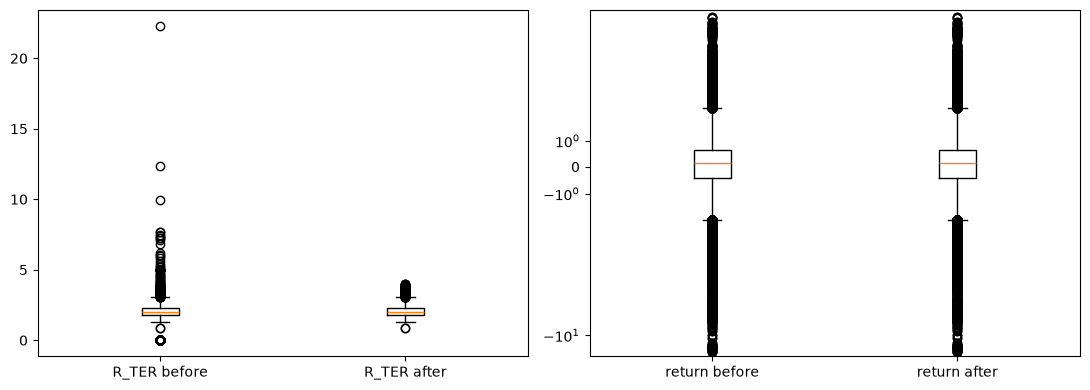

In [54]:
# set the spike NAVs to NaN
nav.loc[spike, "NAV"] = np.nan

# the same methods again on the fixed columns
after = {"ret": nav["NAV"].groupby([nav["MF_ID"], nav["Plan"]]).pct_change(fill_method=None) * 100, "R_TER": ter["R_TER"], "D_TER": ter["D_TER"], "gap": ter["gap"]}
counts_after = pd.DataFrame({name: pd.Series({"z-score": detect_outliers_zscore(x).sum(), "IQR": detect_outliers_iqr(x).sum(),
                                              "modified z": detect_outliers_modified_zscore(x).sum()}) for name, x in after.items()})
display(pd.concat({"before": counts.drop("rows tested"), "after": counts_after}, axis=1))

# before and after figure
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot([tests["R_TER"].dropna(), after["R_TER"].dropna()]); ax[0].set_xticks([1, 2]); ax[0].set_xticklabels(["R_TER before", "R_TER after"])
ax[1].boxplot([r, after["ret"].dropna()]); ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(["return before", "return after"]); ax[1].set_yscale("symlog", linthresh=5)
plt.tight_layout(); plt.show()

# decision log
for p in ["R", "D"]:
    for how, n in ter[f"{p}_TER_fix"][ter[f"{p}_TER_fix"] != ""].value_counts().items():
        log(f"{p}_TER", "outlier (impossible TER)", how, "range 0.05 to 4, parts of the TER, neighbours", int(n))
log("NAV", "one-day spike not explained by the other funds and reversed next day", "NAV set to NaN, class kept in nav_flag", "median of the day + reversal test", int(spike.sum()))
log("NAV", "real market days flagged by z-score/IQR/modified z", "kept", "median of the day", int((big & real).sum()))
log("NAV", "big unexplained days", "kept and flagged in nav_flag", "median of the day + reversal test", int((nav["nav_flag"] == "unexplained_kept").sum()))
log("NAV, TER", "capping or removing flagged values", "not done", "comparison in 6.5", 0)

# helper columns out, TER view refreshed
nav = nav.drop(columns=["ret", "peer", "n_day"])
ter = ter.drop(columns=["gap"])
ter_main = ter[important_cols].copy()
count_rows("outliers handled (values changed, no row removed)")

- **Tested:** daily NAV return (inside MF_ID + Plan), `R_TER`, `D_TER` and their gap, with z-score, IQR, modified z-score and Isolation Forest.
- **Rule:** an outlier is **corrected** if the true value can be found (parts of the TER, decimal slip), **set to NaN** if it is an unrecoverable error (bad NAV print, impossible TER, inverted pair), and **kept** if it is a real market day. Nothing is capped.
- **Finding:** the simple methods flag many NAV days, nearly all real market days. The real errors are a small part of the flags (table in 6.4).
- **Limits:** TER rows are not independent (a value repeats for weeks), so TER flag counts are only a first look. A wrong TER that stays inside 0.05 to 4 and agrees with the parts, or a two-reading blip, is not caught. The error rule for NAV (peer + reversal) is our own, not outside truth.

## 7. DUPLICATES

A duplicate is the same real thing written twice. We look at it on two levels:
1. **Same key twice.** One fund has one NAV per day and one house has one TER row per day. A key that comes twice is a duplicate.
2. **Same thing written differently.** The same scheme with a different spelling (`Mid Cap`, `Mid-Cap`, extra spaces, a new name after a rename). Here we use the steps from the deduplication notebook: standardize, block, compare, classify.

What we do with a repeated key: if the copies agree, keep one. If they disagree on the value we cannot know which is true, so we set the value to NaN and flag it.

The step order matters: this step comes after outliers, so a spike error already set to NaN does not count as a disagreement.

### 7.1 Same key twice

In [55]:
# NAV: one row per MF_ID + Plan + Date. TER: one row per MF_ID + Date
key_nav, key_ter = ["MF_ID", "Plan", "Date"], ["MF_ID", "Date"]
print("NAV rows with a repeated key:", nav.duplicated(key_nav, keep=False).sum(), "| TER rows with a repeated key:", ter.duplicated(key_ter, keep=False).sum())

# copies that disagree on the value (NaN is ignored, so a copy with a value wins over an empty one)
nav_conf = nav.groupby(key_nav)["NAV"].transform("nunique") > 1
ter_conf = (ter.groupby(key_ter)["R_TER"].transform("nunique") > 1) | (ter.groupby(key_ter)["D_TER"].transform("nunique") > 1)
print("rows in disagreeing groups: NAV", nav_conf.sum(), "| TER", ter_conf.sum())

# if the disagreement is everywhere, MF_ID does not identify one scheme and the keys are wrong
assert nav_conf.mean() < 0.01, "too many conflicting NAVs: MF_ID + Plan is not one scheme"
assert ter_conf.mean() < 0.05, "too many conflicting TER rows: MF_ID is not one scheme"

NAV rows with a repeated key: 0 | TER rows with a repeated key: 2675
rows in disagreeing groups: NAV 0 | TER 0


In [56]:
n0_nav, n0_ter = len(nav), len(ter)

# disagreeing copies: value to NaN and flag
nav.loc[nav_conf, "NAV"] = np.nan
nav.loc[nav_conf, "nav_flag"] = "duplicate_conflict"
ter.loc[ter_conf, ["R_TER", "D_TER"]] = np.nan

# keep one row per key, the one with a value first
nav = nav.sort_values(key_nav + ["NAV"], na_position="last").drop_duplicates(key_nav).sort_values(key_nav).reset_index(drop=True)
ter = ter.sort_values(key_ter + ["R_TER", "D_TER"], na_position="last").drop_duplicates(key_ter).sort_values(key_ter).reset_index(drop=True)

assert not nav.duplicated(key_nav).any() and not ter.duplicated(key_ter).any()
log("NAV", "same MF_ID + Plan + Date more than once", "kept one row; NaN where copies disagreed", "key check", n0_nav - len(nav))
log("TER", "same MF_ID + Date more than once", "kept one row; NaN where copies disagreed", "key check", n0_ter - len(ter))
print("rows removed: NAV", n0_nav - len(nav), "| TER", n0_ter - len(ter))
count_rows("duplicate keys removed")

rows removed: NAV 0 | TER 1783


### 7.2 Same scheme written differently

The scheme names in TER can change inside one house (rename, upper/lower case, double spaces). We follow the pipeline of the notebook:
1. **Standardize:** lower case, `mid cap / mid-cap` becomes `midcap`, no punctuation, no words like fund, plan, growth.
2. **Block:** only names of the same `MF_ID` are compared. A house has a few names, so we avoid thousands of useless comparisons.
3. **Compare:** Jaro-Winkler similarity.
4. **Classify:** similarity of 0.85 or more = same scheme (the threshold from the notebook).

The name we keep for a house is its latest spelling (`scheme_label`).

In [57]:
!pip install jellyfish

In [58]:
import jellyfish

# 1) standardize
def standardize(s):
    return (s.str.lower().str.replace(r"mid[\s\-]*cap", "midcap", regex=True).str.replace(r"[^a-z0-9 ]", " ", regex=True)
             .str.replace(r"\b(fund|plan|option|growth|direct|regular|scheme)\b", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())

ter["Scheme_Name"] = ter["Scheme_Name"].str.replace(r"\s+", " ", regex=True).str.strip()
ter["name_std"] = standardize(ter["Scheme_Name"])

# 2) block by MF_ID: the different standardized names of each house
names = ter.groupby("MF_ID")["name_std"].unique()
print("spellings per house, raw names:", ter.groupby("MF_ID")["Scheme_Name"].nunique().value_counts().to_dict(), "| after standardizing:", names.str.len().value_counts().to_dict())

# 3) compare every pair of names inside a house, 4) classify with 0.85
pairs = [(mf, a, b, jellyfish.jaro_winkler_similarity(a, b)) for mf, n in names.items() for i, a in enumerate(n) for b in n[i + 1:]]
pairs = pd.DataFrame(pairs, columns=["MF_ID", "name_1", "name_2", "similarity"])
pairs["same_scheme"] = pairs["similarity"] >= 0.85
pairs

spellings per house, raw names: {1: 16, 2: 10, 4: 4, 3: 3, 5: 1} | after standardizing: {1: 22, 2: 8, 3: 4}


,MF_ID,name_1,name_2,similarity,same_scheme
0,4,baroda midcap,baroda bnp paribas midcap,0.689744,False
1,9,hdfc midcap opportunities,hdfc midcap opportunites,0.992000,True
2,9,hdfc midcap opportunities,hdfc midcap,0.888000,True
3,9,hdfc midcap opportunites,hdfc midcap,0.891667,True
4,17,kotak emerging equity,kotak midcap,0.682540,False
5,21,reliance,nippon india,0.305556,False
6,21,reliance,nippon india midcap,0.399854,False
7,21,nippon india,nippon india midcap,0.926316,True
8,22,sbi magnum midcap,sbi midcap,0.877647,True
9,25,tata midcap dividend,tata midcap,0.910000,True


In [59]:
# one label per house: the latest spelling
ter["scheme_label"] = ter.sort_values("Date").groupby("MF_ID")["Scheme_Name"].transform("last")
ter = ter.drop(columns="name_std")

# the company name in NAV must also be one spelling per house
print("company spellings per MF_ID in NAV:", nav.groupby("MF_ID")["Mutual_Fund_Company"].nunique().value_counts().to_dict())

log("Scheme_Name", "same scheme with different spelling or after a rename inside one house", "extra spaces removed; scheme_label = latest name of the house", "standardize + block on MF_ID + Jaro-Winkler 0.85", int(ter["Scheme_Name"].ne(ter["scheme_label"]).sum()))
ter_main = ter[important_cols].copy()

company spellings per MF_ID in NAV: {1: 33}


### Summary of section 7
- Repeated keys were found on both tables. Copies that agreed were reduced to one row, copies that disagreed got NaN (counts are in the decision log).
- Scheme names are compared only inside the same `MF_ID`. The pairs with similarity of 0.85 or more are the same scheme, and every house now has one `scheme_label`.
- The guard `assert` in 7.1 stops the notebook if the key `MF_ID + Plan` stops identifying one scheme.

## 8. INTEGRATION (joining NAV and TER)

NAV is one row per fund per day. TER is one row per house per day with both plans in it. The two tables can only be joined if they describe the same schemes. We check this in three ways before we join:

1. **By the key:** which houses are in both tables, and for which dates.
2. **By the names:** do the scheme names of NAV and TER of the same `MF_ID` look like the same scheme? We use the notebook's pipeline again (standardize, compare with fuzzy matching). The `MF_ID` is the known answer, so we can also measure how often the names alone would have found the right house.
3. **By the dates:** does every NAV day find a TER row?

In [60]:
# 1) which houses are in which table, and the dates they cover
cover = nav.groupby("MF_ID")["Date"].agg(nav_from="min", nav_to="max").join(ter.groupby("MF_ID")["Date"].agg(ter_from="min", ter_to="max"), how="outer")
print("houses only in NAV:", sorted(set(nav["MF_ID"]) - set(ter["MF_ID"])), "| only in TER:", sorted(set(ter["MF_ID"]) - set(nav["MF_ID"])))
cover

houses only in NAV: [] | only in TER: [55]


,nav_from,nav_to,ter_from,ter_to
MF_ID,,,,
3,2019-01-01,2026-09-30,2019-01-01,2026-09-30
4,2022-03-14,2026-09-30,2019-01-01,2026-09-30
6,2019-01-01,2026-09-30,2019-01-01,2026-09-30
9,2019-01-01,2026-09-30,2019-01-01,2026-09-30
13,2019-01-01,2026-09-30,2019-01-01,2026-09-30
16,2022-11-25,2026-09-30,2022-11-25,2026-09-30
17,2019-01-01,2026-09-30,2019-01-01,2026-09-30
18,2023-07-31,2026-09-30,2023-07-29,2026-09-30
20,2019-01-01,2026-09-30,2019-01-01,2026-09-30


In [62]:
!pip install fuzzywuzzy

In [63]:
from fuzzywuzzy import fuzz, process

# 2) names: the NAV name comes from the raw table (we dropped it in step 4). Growth rows only, one name per house
nav_names = nav_raw[nav_raw["Option"].isin(growth_options)][["MF_ID", "NAV Name"]].drop_duplicates("MF_ID")
nav_names["name_std"] = standardize(nav_names["NAV Name"].str.replace(r"\s+", " ", regex=True))
ter_names = ter.drop_duplicates("MF_ID", keep="last")[["MF_ID", "scheme_label"]]
ter_names["name_std"] = standardize(ter_names["scheme_label"])

# compare the NAV name with every TER name (no blocking) and see if the best match is the house with the same MF_ID
def best_match(name):
    match, score = process.extractOne(name, ter_names["name_std"].tolist(), scorer=fuzz.token_sort_ratio)[:2]
    return pd.Series({"best_ter_name": match, "score": score, "best_MF_ID": ter_names.loc[ter_names["name_std"] == match, "MF_ID"].iloc[0]})

check = nav_names.join(nav_names["name_std"].apply(best_match))
check["same_house"] = check["best_MF_ID"] == check["MF_ID"]
print(f"the name alone finds the right MF_ID for {check['same_house'].mean():.0%} of the houses (score 100 = identical)")
check[["MF_ID", "name_std", "best_ter_name", "score", "same_house"]].sort_values("score").head(8)

/home/krish/project/dcv_midcap_returns_mutual_funds/venv/lib/python3.12/site-packages/fuzzywuzzy/fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


the name alone finds the right MF_ID for 100% of the houses (score 100 = identical)


,MF_ID,name_std,best_ter_name,score,same_house
0,13,quant midcap,quant midcap,100,True
7648,16,jm midcap,jm midcap,100,True
11504,17,kotak midcap,kotak midcap,100,True
19088,18,lic mf midcap,lic mf midcap,100,True
22212,20,icici prudential midcap,icici prudential midcap,100,True
29976,21,nippon india midcap,nippon india midcap,100,True
43233,22,sbi midcap,sbi midcap,100,True
50913,25,tata midcap,tata midcap,100,True


If the names agree with the `MF_ID` for (almost) every house, the `MF_ID` is a safe join key. Houses where they disagree are listed above and should be looked at by hand before we trust the key.

**Dates.** A NAV day may have no TER row on exactly the same date. We join each NAV row with the **last TER row on or before its date**, from the same house, but not older than 35 days. We keep `ter_age_days` so that nobody has to guess how old the TER is. A NAV day with no TER stays in the table with an empty TER (a left join). It is not dropped.

In [64]:
# 3) how many NAV days have a TER row on exactly the same date
same_day = nav.merge(ter[["MF_ID", "Date"]], on=["MF_ID", "Date"], how="left", indicator=True)["_merge"].eq("both").mean()
print(f"NAV rows with a TER row on the same date: {same_day:.1%}")

# join: last TER row on or before the NAV date, same house, not older than 35 days
t = ter[["MF_ID", "Date", "R_TER", "D_TER", "scheme_label"]].rename(columns={"Date": "TER_Date"})
nav_ter = pd.merge_asof(nav.dropna(subset=["Date"]).astype({"Date": "datetime64[ns]"}).sort_values("Date"), t.astype({"TER_Date": "datetime64[ns]"}).sort_values("TER_Date"),
                        left_on="Date", right_on="TER_Date", by="MF_ID", direction="backward", tolerance=pd.Timedelta(days=35))

# the TER of the plan of the row, and how old it is
nav_ter["TER"] = np.where(nav_ter["Plan"].str.startswith("Direct"), nav_ter["D_TER"], nav_ter["R_TER"])
nav_ter["ter_age_days"] = (nav_ter["Date"] - nav_ter["TER_Date"]).dt.days
nav_ter = nav_ter.drop(columns=["R_TER", "D_TER"]).sort_values(["MF_ID", "Plan", "Date"]).reset_index(drop=True)

assert len(nav_ter) == len(nav), "the join changed the number of NAV rows"
print("rows:", len(nav_ter), "| rows with a TER:", nav_ter["TER"].notna().sum(), f"({nav_ter['TER'].notna().mean():.1%})", "| max age of the TER used:", nav_ter["ter_age_days"].max(), "days")

# coverage by house
nav_ter.groupby("MF_ID").agg(rows=("NAV", "size"), with_TER=("TER", lambda s: s.notna().mean()), mean_TER=("TER", "mean"), oldest_TER_days=("ter_age_days", "max")).round(3)

NAV rows with a TER row on the same date: 99.5%
rows: 93824 | rows with a TER: 93153 (99.3%) | max age of the TER used: 19 days


,rows,with_TER,mean_TER,oldest_TER_days
MF_ID,,,,
3,3822,1.000,1.616,3
4,2244,1.000,1.342,1
6,3822,1.000,1.314,4
9,3822,1.000,1.283,19
13,3824,1.000,1.468,2
16,1898,1.000,1.357,1
17,3822,1.000,1.097,5
18,1562,1.000,1.998,0
20,3822,1.000,1.653,0


In [65]:
# sanity: Direct must be cheaper than Regular for every house
mean_ter = nav_ter.pivot_table(index="MF_ID", columns="Plan", values="TER", aggfunc="mean")
wrong = mean_ter[mean_ter["Direct Plan"] >= mean_ter["Regular Plan"]]
print("houses where Direct is not cheaper than Regular:", len(wrong))
wrong

log("NAV, TER", "tables joined on MF_ID + Date (last TER on or before the NAV date, max 35 days)", "left join, no NAV row lost; TER empty where none found", "name check + key coverage + merge_asof", int((nav_ter["TER"].isna()).sum()))

houses where Direct is not cheaper than Regular: 0


### Summary of section 8
- Houses and dates of both tables were compared. The names of NAV and TER agree with the `MF_ID` (percentage printed in 8.2), so `MF_ID` is the join key.
- The join keeps every NAV row (checked with an assert). TER comes from the same house and the plan of the row, and `ter_age_days` shows how old it is.
- Rows with no TER stay with an empty TER. The decision log counts them.
- The table `nav_ter` is saved in step 9 together with `nav` and `ter`.

## 9. Save the clean tables and the log

Four things go into `clean/`: the clean NAV table, the clean TER table, the joined NAV + TER table and the decision log. The log is as important as the data. A cleaned file alone can not be reviewed, because you can see *what* changed by comparing two files but the reasons exist only in the log.

Before saving we drop the helper columns we created for our own use (like `year`), so that the clean tables only hold real columns. The helper below saves each table as Parquet (the working file) and CSV (the copy anyone can open), like in the interim notebook.

In [66]:
ter = ter.drop(columns=["year"], errors="ignore")

def save_clean(df, name):
    df.to_csv(f"clean/{name}.csv", index=False)
    df.to_parquet(f"clean/{name}.parquet", index=False)
    print(name, df.shape)

count_rows("final")

save_clean(nav, "nav_midcap_clean")
save_clean(ter, "ter_midcap_clean")
save_clean(nav_ter, "nav_ter_midcap_joined")
pd.DataFrame(decision_log).to_csv("clean/decision_log.csv", index=False)

nav_midcap_clean (93824, 6)
ter_midcap_clean (68236, 24)
nav_ter_midcap_joined (93824, 10)


In [67]:
print("Decision log")
display(pd.DataFrame(decision_log))
print("Rows after each step")
display(pd.DataFrame(row_counts))

Decision log


,columns,problem,action,method_used,rows_affected
0,Net Asset Value,string instead of number,converted to float64,pd.to_numeric,206239
1,Date,string instead of datetime,converted to datetime,pd.to_datetime,206239
2,Net Asset Value,"zero, negative or non-numeric NAV","none found, nothing changed",pd.to_numeric(errors='coerce') and a <= 0 check,0
3,"TER_Date, TER_Year, Month",three columns that hold the same date,kept one datetime column Date and dropped the ...,pd.to_datetime,0
4,TER numeric columns,numbers stored as text (700190 values),converted to float64,pd.to_numeric,700190
5,TER numeric columns,empty markers written as text (0 values),replaced by NaN,replace with a list of markers,0
6,Date (NAV),14 fund houses have no rows in some years,"reported only, no rows invented",years present per MF_ID,0
7,Date (TER),13 fund houses have no rows in some years,"reported only, no rows invented",years present per MF_ID,0
8,"Scheme Code, NAV Name, ISIN Div Payout/ISIN Gr...","not needed: MF_ID, Plan and Option already ide...",dropped 5 columns,column review,0
9,"Net Asset Value, AMC",names that are not clear,renamed to NAV and Mutual_Fund_Company,rename,0


Rows after each step


,step,nav_rows,ter_rows
0,loaded from interim,206239,70019
1,only growth options kept,93824,70019
2,"outliers handled (values changed, no row removed)",93824,70019
3,duplicate keys removed,93824,68236
4,final,93824,68236
